> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/examples/caribbean.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Caribbean shipping under global and EU rules

[Regional networks](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/regional-networks.html) · deck `simulations/examples/example_5/`

How are a region's own ships affected by global and EU rules, today and if
extended to them?

## The case

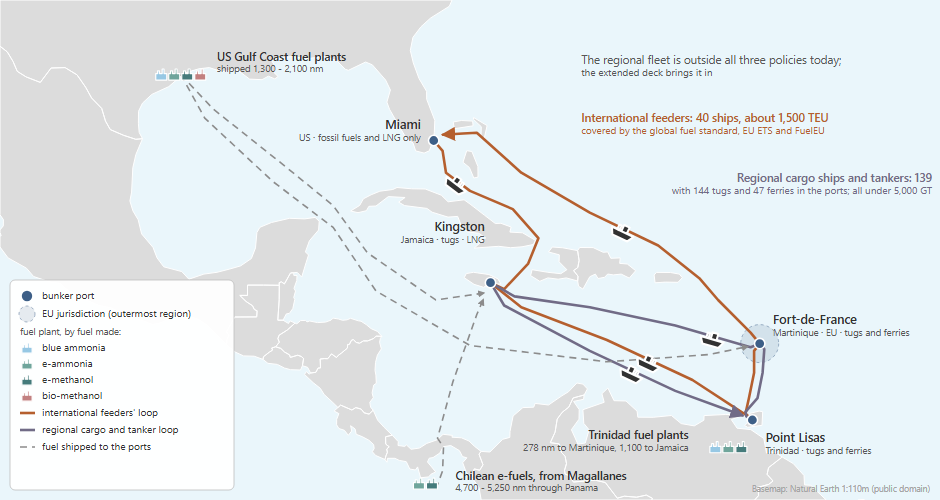

- **Ships:** 330 regional ships (144 tugs, 47 ferries, 85 general cargo ships
  and 54 small tankers), nearly all under 5,000 GT, and 40 container feeders of
  about 1,500 TEU. Fleet counts from the IMO CARES report (2024); the split of
  the cargo ships is INVENTED.
- **Routes:** the feeders on a Miami - Kingston - Trinidad - Martinique loop;
  the regional ships inside and between the three Caribbean ports.
- **Fuels:** blue and e-ammonia, e-methanol and bio-methanol, made in Trinidad,
  on the US Gulf Coast or in Chile and shipped in; LNG at Kingston and Miami only.
- **Policy:** one deck with today's rules (a global fuel standard, the EU ETS and
  FuelEU) on the feeders only. It is run three ways, which differ in whom the
  rules cover: nobody (no policy); the feeders (today's rules); the feeders and
  the regional ships (extended).
- **Horizon:** 2026 to 2050, yearly.

The regional fleet is not calibrated: with the library's world-average ships it
burns more fuel than CARES reports, so compare the runs with each other, not
with the region's real totals.

## Results

In [1]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, even when the `navigate`
# command itself is missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# The example deck.
EXAMPLE = Path("simulations/examples/example_5")
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there."
)


Moved up to the repository root.
Navigate 1.0.0 is already installed.


The cell below solves the deck from 2026 to 2050 three ways, no policy, current rules and extended, and draws their well-to-wake emissions, their freight rate and the fuel they burn, side by side.

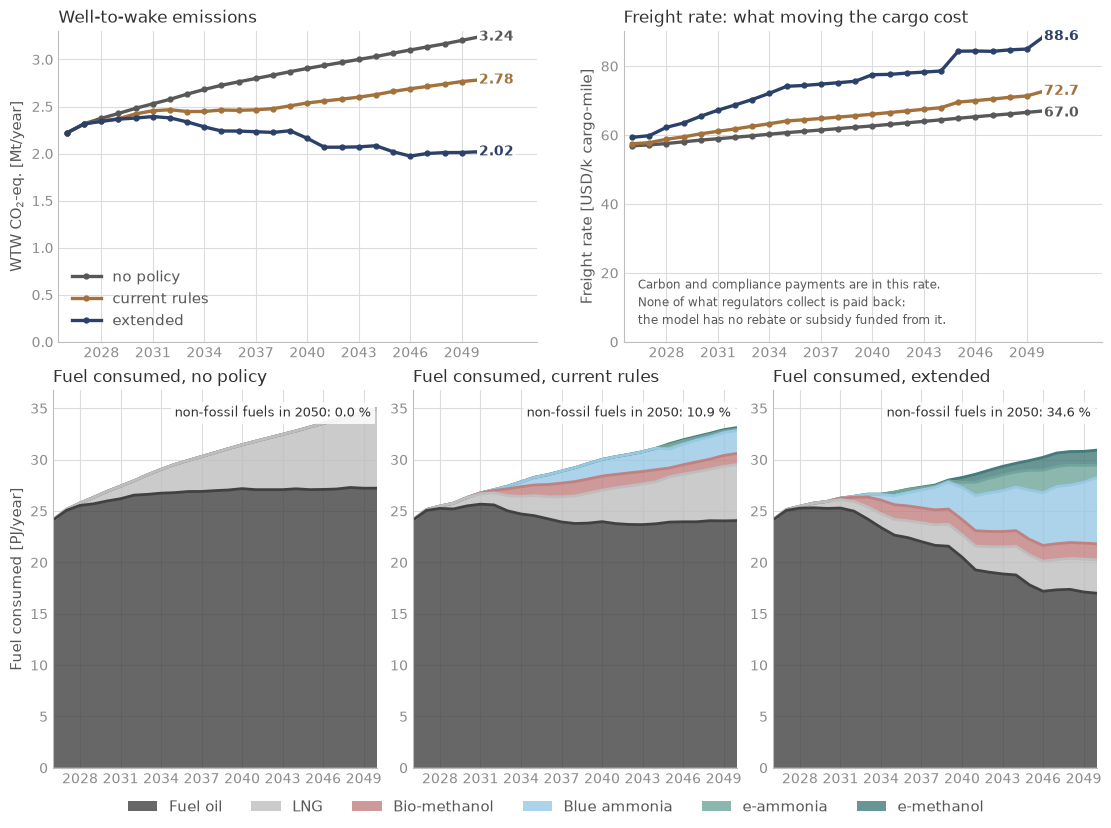

In [2]:
# @title Run the case and see the results
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# The workshop's figure and the functions that fill it, shared with the
# Examples pages: docs/workshop/_results.py.
sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _results import compare_with_previous, plot_cases, print_summary, run_case, scale, summarise
from _solver import guard_interior_point

guard_interior_point()

POLICIES = ["gfs_tier_1", "gfs_tier_2", "eu_ets", "fuel_eu"]


def cover(*patterns):
    """The four regulations cover the vessels matching these patterns, and no other."""
    def tweak(m):
        for name in POLICIES:
            regulation = m.nodes.regulations[name]
            regulation.set_include_vessel("*", "FALSE")
            for pattern in patterns:
                regulation.set_include_vessel(pattern, "TRUE")
    return tweak


NAV = Path("simulations/examples/example_5/example_5.nav")
RUNS = {
    "no policy": cover(),
    "current rules": cover("intl_*"),
    "extended": cover("intl_*", "reg_*"),
}
cases = {label: summarise(run_case(NAV, tweak)) for label, tweak in RUNS.items()}
plot_cases(cases, annotate=True)
plt.show()

# The levers below move this run:
REF_TWEAK, ref = RUNS["extended"], cases["extended"]


# ===========================================================================
#  The machinery for the sensitivity analysis. Nothing to edit here: the
#  levers are further down.
# ===========================================================================
# each lever, and the forecasts it multiplies
LEVERS = {
    "OIL_PRICE": ['fossil_fuel_oil_price_global'],
    "LNG_PRICE": ['liquefied_natural_gas_price_global'],
    "GFS_TIER_1_PRICE": ['gfs_tier_1_price'],
    "EU_ETS_PRICE": ['eu_ets_carbon_credit_price'],
    "AMERICAS_ELECTRICITY_PRICE": ['electricity_cost_americas_mid'],
}
_RUNS = []      # the scenarios solved so far, newest last: (levers, summary)


def run_your_scenario():
    """Solve the levers set in the YOUR SCENARIO cell and compare with
    the extended run and with the scenario solved before it."""
    changed = [(n, globals()[n]) for n in LEVERS if globals()[n] != 1.0]
    if not changed:
        print("Every lever is still at 1.0, so this would just re-solve the deck.")
        print("Change one of the numbers above and run this cell again.")
        return
    tweaks = ([REF_TWEAK] if REF_TWEAK else []) + [scale(f, v) for n, v in changed
                                                   for f in LEVERS[n]]

    def your_scenario(m):
        for t in tweaks:
            t(m)

    label = ",  ".join(f"{n} x {v}" for n, v in changed)
    compare_with_previous(NAV, ref, your_scenario, label, _RUNS, ref_label="extended")
    plt.show()


### Move one lever

Each number multiplies what the deck already says, so 1.0 is the extended run. Set one, run the cell, and compare with the extended run and with the scenario you ran before. As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.

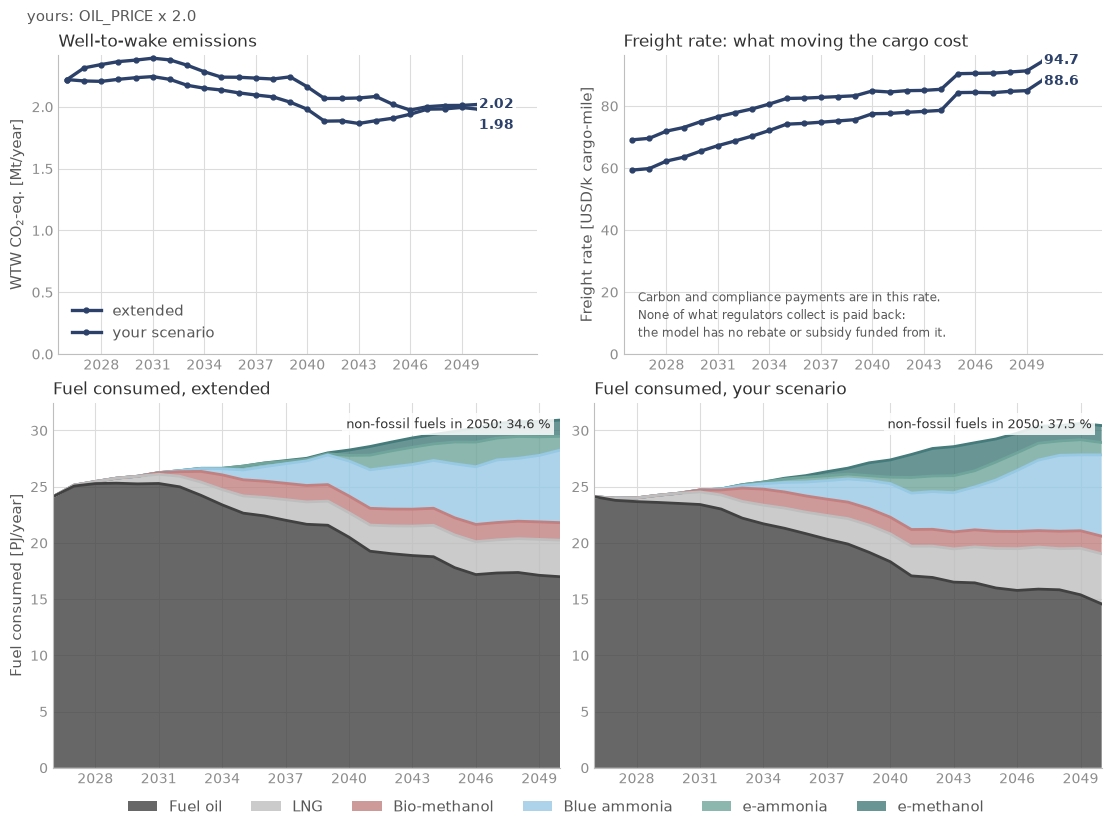

In [3]:
# ===========================================================================
#  YOUR SCENARIO.  Set a lever, then run this cell: it solves your scenario
#  and compares it with the extended run and with the scenario you ran before it.
#
#  Every number is a MULTIPLIER on what the deck already says, so 1.0 is the
#  deck. The right-hand column says what each 1.0 is worth, so you can judge
#  whether a factor of two is a big change or a small one.
#
#  As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.
#  Set OIL_PRICE back to 1.0 to start from the deck.
#
#                                     suggested span  what 1.0 means in the deck
OIL_PRICE                  = 2.0   #  0.7 - 2.0       485 USD/t, flat to 2050
LNG_PRICE                  = 1.0   #  0.7 - 1.6       436 USD/t, flat to 2050
GFS_TIER_1_PRICE           = 1.0   #  0.5 - 4.0       100 USD/t CO2e from 2028 (Tier 2 adds 280 more)
EU_ETS_PRICE               = 1.0   #  0.5 - 3.0       126 USD/t in 2026, 417 by 2050
AMERICAS_ELECTRICITY_PRICE = 1.0   #  0.6 - 1.4       62 USD/MWh in 2026, 41 by 2050: the power e-fuels are made from
# ===========================================================================

run_your_scenario()


## The deck

In [4]:
# @title The deck, tab by tab
import sys
from pathlib import Path

sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _deck import show_deck

show_deck(EXAMPLE, {
    "example_5.nav": ['example_5.nav'],
    "Fleet": ['includes/fleet.inc', 'includes/converter_available.inc'],
    "Route": ['includes/route.inc', 'includes/ports.inc', 'includes/bunker_logistics.inc'],
    "Fuel": ['includes/fuel_production.inc', 'includes/regions.inc', 'includes/producer.inc'],
    "Policy": ['includes/policy_gfs.inc', 'includes/policy_eu.inc', 'includes/extend_to_regional.inc'],
    "Report": ['includes/report.inc'],
})


# ---- example_5.nav ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# EXAMPLE 5 - Caribbean shipping under today's rules.
# The global fuel standard, the EU ETS and FuelEU cover the international ships
# only; the regional fleet, nearly all under 5,000 GT, is outside all three.
# The case's two other runs differ in the policy lines below only: without
# the two policy Includes, no policy; with the third one, the rules extended
# to the regional ships.
# Sources and invented values: README.md.

DEFINE {
    Load DefaultModelDefinition

    Include "includes/fleet.inc"
    Include "includes/route.inc"
    Include "includes/ports.inc"
    Include "includes/bunker_logistics.inc"

    Include "includes/fuel_production.inc"
    Include "includes/regions.inc"
    Include "includes/producer.inc"
    Load DefaultEmission

    Include "includes/policy_gfs.inc"
    Include "includes/policy_eu.inc"
    # Include "includes/extend_to_regional.inc"   # the rules extended to the regional ships

    Load DefaultCalibration
    Include "includes/report.inc"
    Load DefaultPlot
}

EVENTS {
    Include "includes/converter_available.inc"
    Load DefaultTimeStepYearly
}

# ---- includes/fleet.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FLEET - Caribbean shipping in two groups.
#
#   reg_*   the regional fleet: domestic and intra-Caribbean ships, nearly all
#           under 5,000 GT. Counts from the IMO CARES report (2024), "Report on
#           Decarbonization of Domestic Shipping: Insights from Africa and the
#           Caribbean", p.19: 330 ships over 100 GT, 144 of them tugs and 47 ferries.
#   intl_*  the international ships that call at the region's hubs, all over
#           5,000 GT.
#
# Ship designs, costs, lifetimes, age profiles and trade growth are the library's
# own for each class. CARES finds no Caribbean domestic ship running on an
# alternative fuel, so every fleet starts on oil. The library's orderbooks are
# sized for the world fleet and are left out.
#
# NOT CALIBRATED, on purpose: with the library's world-average ships the
# regional fleet burns 419 kt of fuel in 2026, against 309 kt in CARES (+36 %).
# Caribbean ships are smaller (most CARES tugs are 250-300 GT).

# ---- regional: tugs (CARES: 144) -------------------------------------------
Copy Vessel "tug_ice_oil"      "reg_tug_oil"
Copy Vessel "tug_ice_methane"  "reg_tug_methane"
Copy Vessel "tug_ice_methanol" "reg_tug_methanol"
Copy Vessel "tug_ice_ammonia"  "reg_tug_ammonia"

Fleet "reg_tug" {
	Vessels = [Vessel("reg_tug_oil"), Vessel("reg_tug_methane"),
	           Vessel("reg_tug_methanol"), Vessel("reg_tug_ammonia")]
	InitialVessels = 144
	InitialSplit = [1.0, 0.0, 0.0, 0.0]
	InitialAgeDistribution = [Curve("age_dist_tug_oil"), 0, 0, 0]
	TradeGrowth = Forecast("trade_growth_tug")
	AllowSpeedManagement = FALSE
}

# ---- regional: ferries (CARES: 47) -----------------------------------------
# The library's ferry has no ammonia design.
Copy Vessel "ferry_ice_oil"      "reg_ferry_oil"
Copy Vessel "ferry_ice_methane"  "reg_ferry_methane"
Copy Vessel "ferry_ice_methanol" "reg_ferry_methanol"

Fleet "reg_ferry" {
	Vessels = [Vessel("reg_ferry_oil"), Vessel("reg_ferry_methane"),
	           Vessel("reg_ferry_methanol")]
	InitialVessels = 47
	InitialSplit = [1.0, 0.0, 0.0]
	InitialAgeDistribution = [Curve("age_dist_ferry_oil"), 0, 0]
	TradeGrowth = Forecast("trade_growth_ferry")
	AllowSpeedManagement = FALSE
}

# ---- regional: cargo and tankers (CARES: the other 139) --------------------
# CARES lists general cargo, product and chemical tankers, ro-ro, container ships
# and offshore supply vessels, but gives their counts only in a chart that could
# not be read. INVENTED: the 139 split as 85 general cargo ships and 54 small
# tankers, with the other types folded into these two.
Copy Vess

## Build it with an AI assistant

This deck was built from the prompt below by an assistant that saw only the
prompt. A new regional network starts from it, or from the case whose routes
look most like yours. [Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html)
shows how to use it.

<details>
<summary>Full prompt for this case</summary>

<!-- tested-prompt: e8b938eb289f -->
**A region's own ships, and rules that do not reach them yet.** 330 domestic and intra-Caribbean ships (tugs, ferries, general cargo ships and small tankers), nearly all under 5,000 GT, and 40 container feeders on a Miami - Jamaica - Trinidad - Martinique loop, 2026 to 2050. New fuels are made in Trinidad, on the US Gulf Coast or in Chile, and shipped in. One deck, run three ways: no policy; today's rules, a global fuel standard as drafted at the IMO plus the EU ETS and FuelEU with Martinique as the EU port, which cover the feeders only; and the same rules extended to the regional ships. The question is how the region's own ships are affected, today and if the rules reached them.

**Built on public data, with gaps.** The fleet counts come from the IMO CARES report on domestic shipping (2024). The split of the cargo ships, the distances, speeds, delivery costs and the region's share of plant building are INVENTED, and the prompt marks each one. The regional fleet is not calibrated: with the library's world-average ships it burns more fuel than CARES reports, so compare the decks with each other, not with the region's real totals.


**Tested:** 2026-10-28, built cold twice. After the first build the prompt gained
explicit port times, speed management and production pathways; the second build
ran first time with no warnings: the regional ships burnt 418.5 kt in 2026 (CARES:
309 kt), and summed 47.9 Mt without policy against 39.3 Mt with the rules extended
to them. It was one of Session 5's examples until it moved here the same day.

````text
You are helping me build a simulation study for Navigate, the shipping
decarbonisation model. Write the files yourself; do not only
describe them.

Before writing anything, find the Navigate repository on my machine (a folder
usually named navigate-zcs; ask me where it is if you cannot find it), then read
docs/workshop/building-a-deck.md in it and follow it. It
says how Navigate works, how to run a deck and read its results, and the rules
every deck follows. This prompt gives the case.

THE DECK
A new folder, simulations/user/caribbean/, holding one deck, caribbean.nav, with
today's rules: a global fuel standard, the EU ETS and FuelEU, covering the
international ships only. The case is run three ways, which differ in the
deck's policy Include lines only:
- no policy: without the two policy Include lines
- current rules: the deck as it is
- extended: with a third line, Include "includes/extend_to_regional.inc", read
  after the policy files, which extends the rules to the regional ships. Leave
  it in the deck commented out, saying what it does.

THE CASE
Caribbean shipping, 2026 to 2050, yearly steps. The question: how are the
region's own ships affected by global and EU policy, today and if the rules
were extended to them?
- Regional fleet: domestic and intra-Caribbean ships, nearly all under
  5,000 GT, so outside all three policies today. 144 tugs and 47 ferries (IMO
  CARES 2024, "Report on Decarbonization of Domestic Shipping: Insights from
  Africa and the Caribbean", p.19), plus 85 general cargo ships and 54 small
  tankers (INVENTED: CARES's other 139 ships, split between the two). Library
  classes tug, ferry, general_cargo and tanker_7500_dwt.
- International fleet: 40 container feeders (INVENTED count) of the library's
  container_1500_teu class; the region's feeders are 500-2,500 TEU.
- Every fleet starts on fuel oil: CARES finds no alternative-fuel ship in the
  region. Leave out the library's orderbooks, which are sized for the world
  fleet. The library's ferry has no ammonia design.
- Ports: jamaica (Kingston), trinidad (Port of Spain and Point Lisas),
  martinique (Fort-de-France, an EU outermost region, so the EU's one port
  here) and miami.
- Routes:
  - tugs work inside the three Caribbean ports: a REGIONAL_TRIP with their
    work split by 2025 container throughput (INVENTED proxy), jamaica 0.78,
    trinidad 0.17, martinique 0.05, and the library profile's 50 port calls a
    year split the same way (39, 8.5, 2.5);
  - ferries: a REGIONAL_TRIP, half in trinidad and half in martinique
    (INVENTED), 25 port calls a year at each;
  - regional cargo ships and tankers: a ROUND_TRIP loop trinidad - martinique -
    jamaica and back, legs 278, 1,021 and 1,100 nm. Cargo ships at 11.2 kn and
    half full on every leg, 2.45 days per port call. Tankers at 10.5 kn
    (INVENTED), full out of trinidad, half full after martinique and empty
    home (INVENTED), 7.4 days per port call;
  - feeders: a ROUND_TRIP loop miami - jamaica - trinidad - martinique and back
    to miami, legs 700, 1,100, 278 and 1,393 nm, at 13 kn (INVENTED), 70 %
    full, 2.5 days per port call.
  The distances are great-circle plus 10 % (INVENTED); miami - jamaica is set
  at 700 nm because the great circle crosses Cuba (INVENTED). The tugs' and
  ferries' speed, time at sea and capacity use come from each class's
  operational profile in the library; the port times above are this case's.
- Speed management as each library class has it: off for tugs and ferries;
  on for cargo ships and tankers (a maximum change of 0.4) and feeders (0.5).
  It can raise a speed above the one set as well as lower it.
- No energy-efficiency technologies: leave the library's out.
- Fuels: fuel oil at every port and LNG at jamaica and miami only (INVENTED),
  both at the library's global prices. Blue ammonia, e-ammonia, e-methanol and
  bio-methanol can be bunkered at the three Caribbean ports, not at miami.
- Fuel production, three sites shipping to the ports:
  - Trinidad, a new region "caribbean": blue ammonia, e-ammonia and e-methanol.
    Renewable power at the library's electricity_cost_americas_mid (INVENTED
    proxy); a grid at 62 USD/MWh (GlobalPetrolPrices, June 2025) and
    0.682 t CO2e/MWh (Ember via Our World in Data, 2024), both held flat
    (INVENTED); natural gas at the library's global price.
  - The US Gulf Coast, the library's "americas" region: the same three, plus
    bio-methanol.
  - Chile, a new region "chile": e-ammonia and e-methanol on the library's
    electricity_cost_americas_low (INVENTED proxy for Magallanes wind).
  E-fuels by alkaline electrolysis, bio-methanol by gasification. Every
  plant's cost of capital is the library's americas forecast for its kind
  (blue, electro or bio): the library has none for the Caribbean or Chile.
- Policy:
  - The global fuel standard, as the IMO Net-Zero Framework was drafted at
    MEPC 83: two regulations that add up, against a reference of 93.3 gCO2e/MJ.
    gfs_tier_1 sets the direct compliance target, -17 % in 2028, -21 % in 2030
    and -43 % in 2035, and charges 100 USD/t CO2e below it. gfs_tier_2 sets the
    base target, -4 %, -8 % and -30 %, and charges a further 280 USD/t below it
    (380 in all). Both start in 2028 and are held flat after their last point
    (INVENTED). Well-to-wake, on intensity, with surplus units pooled freely;
    jurisdiction all four ports; it covers the international ships.
  - The EU ETS and FuelEU: the library's own regulations, imported, with
    martinique as their only port; they cover the international ships. They
    name fuels this case does not bunker (FAME, e-diesel, bio-methane,
    e-methane): import those too, or the deck will not parse.
  - In the extended run, all four also cover the regional ships.

HOW TO BUILD IT
Build it node by node, as building-a-deck.md describes for a deck on named
ports. Name the vessels and fleets reg_tug, reg_ferry, reg_cargo, reg_tanker
and intl_feeder (vessels reg_tug_oil, ... with Copy Vessel), so that a policy
can cover "intl_*" or "reg_*". Each fleet keeps its library class's age
profile, trade growth and fuel conversion costs. For the second and third
production sites, Copy Plant the first site's plants, each with its own Region,
Source and CostOfCapital. One producer per site, each with the same share of
the library's plant-building capacity and feedstock pools, below. When the new
engines can be ordered: the library's DefaultConverterAvailable dates for each
class, written out for this deck's fleet names. Add a Report with, per fleet,
ExistingVessels, FuelTypeEnergy, TotalConsumedMass, TotalEquivalentWTW,
FuelExpenses and RegulationExpenses; per vessel, ActualSpeed; and per port the
bunker price.

NUMBERS
Everything not listed here or above comes from the library, by name. Mark
every INVENTED number where it appears and list them all in the .nav headers.
- Bunker delivery, nm: Trinidad's plants to trinidad 15, martinique 278,
  jamaica 1,100; the Gulf Coast to jamaica 1,300, martinique 2,000, trinidad
  2,100 (INVENTED); Chile to jamaica 4,700, trinidad and martinique 5,250,
  measured along a sea route through the Panama Canal, tolls not counted. 0.02 USD per ton per nm
  (INVENTED).
- Each producer's share of shipping's plant-building capacity: 0.02
  (INVENTED).
- Each producer's share of shipping's biogenic CO2 and biomass: 0.002
  (INVENTED).

BEFORE YOU TELL ME IT WORKS
Run the deck three ways, one after the other, by changing its policy Include
lines as above and putting them back afterwards, and report on each run as
building-a-deck.md says. Then, from the three reports, give me side by side,
for the regional ships and for the feeders separately:
- the oil share of their energy in 2050;
- their well-to-wake emissions in 2050, and summed over 2026-2050;
- their fuel and policy bill summed over 2026-2050 (FuelExpenses plus
  RegulationExpenses).
Say plainly whether today's rules change anything for the regional ships, and
what extending the rules to them does; say how much of any cut comes from
slower speeds rather than other fuels. Remind me that the regional fleet is
not calibrated: give its fuel burnt in 2026 next to the 309 kt CARES reports,
so the differences between the runs matter, not the totals. Remind me which
inputs are INVENTED.
````

</details>

## Run it yourself

In Colab: the badge at the top of this page opens it as a notebook, which runs
the deck three ways and lets you move the levers. Nothing to install.

On your machine, install Navigate first: follow the [installation steps in the README](https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/README.md#installation),
or the more detailed [Getting started](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/tutorials/getting_started.html) tutorial.
Then run the deck from the repository root:

```bash
python -m navigate simulations/examples/example_5/example_5.nav -d ./assumptions
```

To make a case of your own, copy the folder to `simulations/user/` and change
it, or have an AI assistant build one from the prompt above, as
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows.